# 9. The scheme, step by step

In this notebook, we follow two operations of the numerical scheme of
J.-M. Mirebeau, provided by the agd library, on two worked examples small
enough to check by hand:

- turning a single control vector into an adaptive stencil, using Selling's
  decomposition of a relaxed quadratic form;
- performing one update of the value function at one grid point from that
  stencil.

Notebooks 1 to 8 use the solver as a black box: given a control set, an
obstacle map and a pair of poses, it returns a value function. The CUDA kernel
performs the two operations above at every point of the $(x, y, \theta, s)$
grid, several million times per solve. Here they are performed once, in NumPy,
with every intermediate quantity printed. Every value below is computed here,
not quoted; where the thesis prints the same quantity, we compare the two.

**Summary**

1. [From a control vector to a quadratic form](#1)
2. [Selling's decomposition](#2)
3. [How good is the approximation](#3)
4. [One update of the value function](#4)
5. [Why the smallest root](#5)
6. [What the solver runs](#6)

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))

import numpy as np
import matplotlib.pyplot as plt

from shfm.figures import save
from shfm.solver import agd_location

# The vendored agd, put ahead of any installed copy, as the solver does.
print("agd in use:", os.path.relpath(agd_location(), ".."))
from agd import Selling

plt.rcParams.update({"figure.dpi": 110, "font.size": 11})
np.set_printoptions(precision=4, suppress=True)

agd in use: external/agd/agd


<a id='1'></a>
## 1. From a control vector to a quadratic form

At a configuration $q$ the vehicle may move along a small set of velocities
$u_i(q)$, built in notebook 1. The eikonal equation

$$ \max_{1 \le i \le I} \langle \nabla U(q), u_i(q) \rangle_+ = c(q) $$

is a maximum of one-dimensional constraints, and each of them involves the rank-one
quadratic form $\langle p, u_i \rangle^2$. A rank-one form is degenerate: it has no
inverse, it cannot be decomposed over a lattice, and a scheme built on it would
propagate information along a single line rather than through a neighbourhood.

The scheme relaxes it. With $u \equiv u_i(q)$, the relaxed form is

$$ M_{\epsilon,i}(q) = u \otimes u + \epsilon^2 \left( I_d - u \otimes u \right) $$

which is $u \otimes u$ along $u$ for a unit control, and $\epsilon^2$ in every
orthogonal direction.
It is positive definite for $\epsilon > 0$, so it can be decomposed, and it
differs from the degenerate form by $O(\epsilon^2)$. We take
$\epsilon = 0.1$, which is the solver's default.

The worked example is the configuration $q = (0, 0, \pi/4)$ with a control that
turns, $u_1(q) = (\cos\theta, \sin\theta, \omega)$ with $\omega = 0.5$.

In [2]:
theta = np.pi / 4
omega = 0.5
u1 = np.array([np.cos(theta), np.sin(theta), omega])
eps = 0.1

M = np.outer(u1, u1) + eps ** 2 * (np.eye(3) - np.outer(u1, u1))

print("u1(q) =", u1)
print("||u1|| =", np.linalg.norm(u1))
print("\nM_eps,1(q) =")
print(M)

u1(q) = [0.7071 0.7071 0.5   ]
||u1|| = 1.1180339887498951

M_eps,1(q) =
[[0.505  0.495  0.35  ]
 [0.495  0.505  0.35  ]
 [0.35   0.35   0.2575]]


Two remarks. First, the form is not normalised: $\|u_1\|^2 = 1.25$, because
the angular component is in radians per unit length and is not commensurable
with the translational one. Second, the third row and column are small but not
negligible; they couple the spatial and angular axes of the stencil.

<a id='2'></a>
## 2. Selling's decomposition

A finite-difference scheme needs offsets on the grid, that is *integer* vectors.
Selling's algorithm writes any positive definite $3 \times 3$ matrix as a
non-negative combination of rank-one terms built on integer offsets:

$$ M = \sum_{i<j} \rho_{ij} \, g_{ij} \otimes g_{ij}, \qquad
   \rho_{ij} \ge 0, \quad g_{ij} \in \mathbb{Z}^3 $$

with $d(d+1)/2 = 6$ terms in dimension 3. The offsets come from an *obtuse
superbase* of the lattice, found by an iterative reduction; the weights are the
negated pairwise scalar products $\rho_{ij} = -\langle b_i, M b_j \rangle$, which
the obtuseness condition makes non-negative. The decomposition is exact, not a
fit, and it adapts to the matrix: a strongly anisotropic $M$ yields long offsets
aligned with its dominant eigenvector.

We start in two dimensions, where the decomposition has three terms and can be
drawn. We take a unit control at $25^\circ$ and $\epsilon = 0.2$. The point
$q + u$ falls between grid nodes, and $M_\epsilon$ decomposes exactly on three
grid offsets.

In [3]:
# Two dimensions: a unit control at 25 degrees, eps = 0.2.
t2d, eps2d = np.radians(25.0), 0.2
u2d = np.array([np.cos(t2d), np.sin(t2d)])
M2d = np.outer(u2d, u2d) + eps2d ** 2 * (np.eye(2) - np.outer(u2d, u2d))
w2d, g2d = Selling.Decomposition(M2d)
g2d = np.array([g if g @ u2d >= 0 else -g for g in g2d.T]).round().astype(int)

print(" rho_j    g_j      angle")
for k in np.argsort(w2d)[::-1]:
    print("  %.3f   (%d, %d)   %4.1f deg"
          % (w2d[k], *g2d[k], np.degrees(np.arctan2(g2d[k][1], g2d[k][0]))))
print("\nFrobenius error of the reconstruction: %.2e"
      % np.linalg.norm(sum(w * np.outer(g, g) for w, g in zip(w2d, g2d)) - M2d))

# The weights the thesis prints for this decomposition.
printed_2d = {(2, 1): 0.156, (1, 1): 0.055, (1, 0): 0.148}
print("\n offset   printed   computed")
for g, rho_ref in printed_2d.items():
    k = [tuple(x) for x in g2d].index(g)
    print("  %-7s  %.3f     %.3f   %s" % (str(g), rho_ref, w2d[k],
          "same" if "%.3f" % rho_ref == "%.3f" % w2d[k] else "DIFFERENT"))

 rho_j    g_j      angle
  0.156   (2, 1)   26.6 deg
  0.148   (1, 0)    0.0 deg
  0.055   (1, 1)   45.0 deg

Frobenius error of the reconstruction: 0.00e+00

 offset   printed   computed
  (2, 1)   0.156     0.156   same
  (1, 1)   0.055     0.055   same
  (1, 0)   0.148     0.148   same


The heaviest weight goes to $(2,1)$, at $26.6^\circ$, the grid direction closest
to $u$; $(1,0)$ and $(1,1)$, on either side, share the rest. In three dimensions,
for the vehicle, the same reduction gives six terms.

In [4]:
weights, offsets = Selling.Decomposition(M)
offsets = offsets.T          # one row per offset

# Orient each offset so that it points along the control.
offsets = np.array([g if g @ u1 >= 0 else -g for g in offsets])

order = np.argsort(weights)[::-1]
print(" rho_ij    g_ij")
for k in order:
    print("  %.3f   (%2d, %2d, %2d)" % (weights[k], *offsets[k].astype(int)))

reconstructed = sum(w * np.outer(g, g) for w, g in zip(weights, offsets))
print("\nFrobenius error of the reconstruction: %.2e"
      % np.linalg.norm(reconstructed - M))

 rho_ij    g_ij
  0.095   ( 1,  1,  1)
  0.030   ( 3,  3,  2)
  0.022   ( 2,  2,  1)
  0.010   ( 2,  1,  1)
  0.010   ( 1,  2,  1)
  0.000   ( 0,  1,  0)

Frobenius error of the reconstruction: 0.00e+00


The reconstruction is exact to machine precision. We compare below the weights,
sorted by decreasing magnitude, with the values the thesis prints for this same
decomposition:

In [5]:
appendix = [(0.095, (1, 1, 1)), (0.030, (3, 3, 2)), (0.022, (2, 2, 1)),
            (0.010, (1, 2, 1)), (0.010, (2, 1, 1)), (0.000, (1, 0, 0))]

print("     appendix            computed           offsets match")
for k, (rho_ref, g_ref) in zip(order, appendix):
    g_here = tuple(abs(offsets[k].astype(int)))
    same = sorted(g_here) == sorted(map(abs, g_ref))
    print("  %.3f  %-11s  %.3f  %-11s  %s"
          % (rho_ref, str(g_ref), weights[k], str(tuple(offsets[k].astype(int))),
             "yes" if same else "NO"))

     appendix            computed           offsets match
  0.095  (1, 1, 1)    0.095  (1, 1, 1)    yes
  0.030  (3, 3, 2)    0.030  (3, 3, 2)    yes
  0.022  (2, 2, 1)    0.022  (2, 2, 1)    yes
  0.010  (1, 2, 1)    0.010  (2, 1, 1)    yes
  0.010  (2, 1, 1)    0.010  (1, 2, 1)    yes
  0.000  (1, 0, 0)    0.000  (0, 1, 0)    yes


The offsets that carry a weight are recovered up to sign and up to the
ordering of the superbase,
both of which are free: $g \otimes g$ is even in $g$, and the six terms of the
sum commute. The $\rho_{23} = 0$ entry is a degenerate pair, and the
corresponding offset drops out of the stencil: the scheme uses five neighbours
here, not six.

The largest weight, $0.095$, sits on the short
offset $(1,1,1)$, while the small weights sit on long ones such as $(3,3,2)$.
All the weighted offsets point close to the control, within 16.8 degrees of
$u_1$ (section 3).

<a id='3'></a>
## 3. How good is the approximation

The stencil stands for the squared directional derivative
$\langle \nabla U, u_1 \rangle_+^2$, with
$\langle \cdot, \cdot \rangle_+ = \max\{0, \langle \cdot, \cdot \rangle\}$.
Each of its offsets compares $U(q)$ with the neighbour the control comes
from, $q - h\,g_{ij}$ once the offsets are oriented along the control,
$\langle g_{ij}, u_1 \rangle \ge 0$, as above. We consider a function $U$
that is linear near $q$, with gradient $p$. Then
$U(q) - U(q - h\,g_{ij}) = h \langle p, g_{ij} \rangle$ exactly, and the
left-hand side of the discrete equation becomes $h^2 F(p)$, with

$$ F(p) = \sum_{\rho_{ij} > 0} \rho_{ij} \langle p, g_{ij} \rangle_+^2 , $$

where the exact equation has $\langle p, u_1 \rangle_+^2$. The difference
$F(p) - \langle p, u_1 \rangle_+^2$ is the consistency error of the stencil for
the gradient $p$. The thesis bounds it on both sides: for every
$p \in \mathbb{R}^3$,

$$ \langle p, u_1 \rangle_+^2 \;\le\; F(p) \;\le\;
   \langle p, u_1 \rangle_+^2 + \epsilon^2 \|u_1\|^2 \|p\|^2 . $$

The error is $O(\epsilon^2)$, so halving $\epsilon$ divides it by four; the cost
is a worse-conditioned $M$ and therefore longer offsets and a wider stencil.
Both are checked at the end of this section.

We first check the bound on the witness vector $p = (1, 0, 0)$.

In [6]:
def stencil_form(p):
    return (weights * np.maximum(0.0, offsets @ p) ** 2).sum()

p = np.array([1.0, 0.0, 0.0])
direct = max(0.0, p @ u1) ** 2
bound = eps ** 2 * (u1 @ u1) * (p @ p)

print("direct    <p, u1>_+^2       = %.3f" % direct)
print("stencil   sum rho <p,g>_+^2 = %.3f" % stencil_form(p))
print("gap                          = %.3f" % (stencil_form(p) - direct))
print("consistency bound            = %.4f" % bound)

direct    <p, u1>_+^2       = 0.500
stencil   sum rho <p,g>_+^2 = 0.505
gap                          = 0.005
consistency bound            = 0.0125


The gap is $0.005$, under the $0.0125$ bound. The thesis reports $0.003$ for
the same check; the difference is the three-decimal rounding of the weights in
its printed table.

A single witness vector does not establish a bound that holds for *every* $p$:
we sweep twenty thousand random unit directions.

In [7]:
rng = np.random.default_rng(0)
P = rng.normal(size=(20000, 3))
P /= np.linalg.norm(P, axis=1, keepdims=True)   # unit directions, uniform on the sphere
align = P @ u1                                  # <p, u1>, between -||u1|| and ||u1||


def gaps(weights, offsets):
    "F(p) - <p, u1>_+^2 for every row p of P, offsets oriented along u1."
    F = (np.maximum(0.0, P @ offsets.T) ** 2 * weights).sum(axis=1)
    return F - np.maximum(0.0, align) ** 2


gap = gaps(weights, offsets)
print("upper bound violated : %d / %d" % ((gap > bound + 1e-12).sum(), len(P)))
print("lower bound violated : %d / %d" % ((gap < -1e-12).sum(), len(P)))
print("largest gap          : %.2e, at <p, u1> = %.2f" % (gap.max(), align[gap.argmax()]))
print("smallest gap         : %.2e, at <p, u1> = %.3f  (||u1|| = %.3f)"
      % (gap.min(), align[gap.argmin()], np.linalg.norm(u1)))
print("eps^2 (||u1||^2 - 1) : %.2e" % (eps ** 2 * (u1 @ u1 - 1)))

upper bound violated : 0 / 20000
lower bound violated : 1068 / 20000
largest gap          : 9.84e-03, at <p, u1> = 0.12
smallest gap         : -2.50e-03, at <p, u1> = 1.118  (||u1|| = 1.118)
eps^2 (||u1||^2 - 1) : 2.50e-03


The upper bound holds everywhere. The lower bound fails on about five percent
of the directions, those closest to $u_1$, by at most
$\epsilon^2(\|u_1\|^2 - 1) = 2.5 \times 10^{-3}$, reached at
$p = u_1 / \|u_1\|$. The decomposition is exact, so the cause lies in the form
it decomposes. For any $p$,

$$ p^\top M_{\epsilon,1}\, p = (1 - \epsilon^2) \langle p, u_1 \rangle^2 + \epsilon^2 \|p\|^2 , $$

so along $u_1$ the relaxation takes away
$\epsilon^2 \langle p, u_1 \rangle^2 = \epsilon^2 \|u_1\|^2 \|p\|^2$ and gives
back only $\epsilon^2 \|p\|^2$, which is less since $\|u_1\|^2 = 1.25$. agd
scales the isotropic term by $\|u\|^2$ (`self_outer_relax_v` in
`external/agd/agd/Eikonal/HFM_CUDA/cuda/Geometry_.h`, called with
$\epsilon^2$ by `Decomp_v_.h`):

$$ M^{\rm agd}_{\epsilon,1} = u_1 \otimes u_1 + \epsilon^2 \left( \|u_1\|^2 I_d - u_1 \otimes u_1 \right) . $$

The two forms coincide for a unit control. The worked example of the thesis,
reproduced in sections 1 and 2, uses the first, as its appendix states; the
kernel decomposes the second.

Both bounds follow from three facts: $\sum \rho_{ij}\, g_{ij} \otimes g_{ij} = M$,
$\rho_{ij} \ge 0$ and $\langle g_{ij}, u_1 \rangle \ge 0$.

* **Upper bound.** If $\langle p, u_1 \rangle \ge 0$, replacing each
  $\langle p, g_{ij} \rangle_+^2$ by $\langle p, g_{ij} \rangle^2$ can only
  increase the sum, so $F(p) \le p^\top M p$. If $\langle p, u_1 \rangle < 0$,
  remove from $p$ its component along $u_1$: what remains, $p_\perp$, is
  orthogonal to $u_1$, and $\langle p, g_{ij} \rangle \le \langle p_\perp, g_{ij} \rangle$
  for every offset, so $F(p) \le p_\perp^\top M p_\perp$. Either way the gap is at
  most $\epsilon^2 \|p\|^2$ with the form of the example and
  $\epsilon^2 \|u_1\|^2 \|p\|^2$ with agd's: the upper bound of the thesis holds
  for both.
* **Lower bound.** If $\langle p, u_1 \rangle > 0$, the sum
  $\sum \rho_{ij} \langle p, g_{ij} \rangle_+ \langle g_{ij}, u_1 \rangle$ is at
  least $p^\top M u_1$, and the Cauchy-Schwarz inequality gives
  $F(p) \ge (p^\top M u_1)^2 / (u_1^\top M u_1)$. With agd's form
  $p^\top M u_1 = \|u_1\|^2 \langle p, u_1 \rangle$ and
  $u_1^\top M u_1 = \|u_1\|^4$, so $F(p) \ge \langle p, u_1 \rangle^2$: the lower
  bound of the thesis. With the form of the example the same steps give only
  $F(p) \ge \left(1 - \epsilon^2 (1 - \|u_1\|^{-2})\right) \langle p, u_1 \rangle^2$;
  for a unit $p$, where $\langle p, u_1 \rangle \le \|u_1\|$, the gap can then
  fall to $-\epsilon^2(\|u_1\|^2 - 1)$ and no lower, as found above.

The same sweep on agd's form:

In [8]:
# The form the kernel decomposes: the isotropic term scaled by ||u1||^2.
M_agd = np.outer(u1, u1) + eps ** 2 * ((u1 @ u1) * np.eye(3) - np.outer(u1, u1))
w_agd, g_agd = Selling.Decomposition(M_agd)
g_agd = np.array([g if g @ u1 >= 0 else -g for g in g_agd.T])
gap_agd = gaps(w_agd, g_agd)

print(" rho_ij    g_ij")
for k in np.argsort(w_agd)[::-1]:
    print("  %.3f   (%2d, %2d, %2d)" % (max(w_agd[k], 0.0) + 0.0, *g_agd[k].astype(int)))
print("\nupper bound violated : %d / %d" % ((gap_agd > bound + 1e-12).sum(), len(P)))
print("lower bound violated : %d / %d" % ((gap_agd < -1e-12).sum(), len(P)))
print("largest gap          : %.2e, at <p, u1> = %.2f" % (gap_agd.max(), align[gap_agd.argmax()]))

# Widest angle between u1 and an offset that carries a weight. The kernel drops
# the offsets beyond arccos(sqrt(2/3)) = 35.3 deg (Decomp_v_.h).
for name, w, g in (("example", weights, offsets), ("agd", w_agd, g_agd)):
    act = w > 1e-12
    cos = (g[act] @ u1) / np.linalg.norm(g[act], axis=1) / np.linalg.norm(u1)
    print("%-8s widest angle between u1 and a weighted offset: %.1f deg"
          % (name, np.degrees(np.arccos(cos.min()))))

 rho_ij    g_ij
  0.112   ( 1,  1,  1)
  0.032   ( 2,  2,  1)
  0.023   ( 3,  3,  2)
  0.013   ( 2,  1,  1)
  0.012   ( 1,  2,  1)
  0.000   ( 0,  1,  0)

upper bound violated : 0 / 20000
lower bound violated : 0 / 20000
largest gap          : 1.23e-02, at <p, u1> = 0.13
example  widest angle between u1 and a weighted offset: 16.8 deg
agd      widest angle between u1 and a weighted offset: 16.8 deg


The offsets are the same as with the form of the example, the weights are
larger except on $(3,3,2)$, and neither bound is violated. Every offset that
carries a weight lies
within 17 degrees of $u_1$, inside the 35 degrees beyond which the kernel
drops an offset, so that pruning changes nothing here.

The figure plots the gap against the alignment, for both forms.

band of partial activity: |<p, u1>| < 0.32


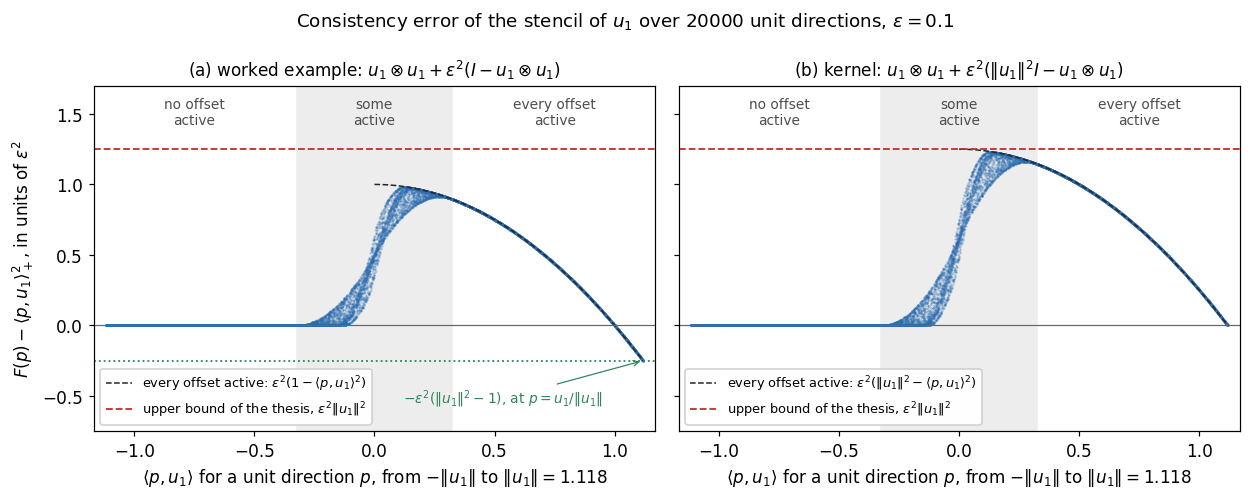

In [9]:
norm_u = np.linalg.norm(u1)
act = weights > 1e-12
widest = np.arccos(((offsets[act] @ u1) / np.linalg.norm(offsets[act], axis=1) / norm_u).min())
edge = norm_u * np.sin(widest)      # |<p, u1>| beyond which every offset is on the same side of p
print("band of partial activity: |<p, u1>| < %.2f" % edge)

a = np.linspace(0.0, norm_u, 200)
panels = ((r"(a) worked example: $u_1 \otimes u_1 + \epsilon^2 (I - u_1 \otimes u_1)$", gap, 1.0 - a ** 2,
           r"$\epsilon^2(1 - \langle p, u_1 \rangle^2)$"),
          (r"(b) kernel: $u_1 \otimes u_1 + \epsilon^2 (\|u_1\|^2 I - u_1 \otimes u_1)$", gap_agd,
           norm_u ** 2 - a ** 2,
           r"$\epsilon^2(\|u_1\|^2 - \langle p, u_1 \rangle^2)$"))

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6), sharey=True)
for ax, (title, g, parabola, plabel) in zip(axes, panels):
    ax.axvspan(-edge, edge, color="0.93", zorder=0)
    ax.scatter(align, g / eps ** 2, s=2, alpha=0.3, color="#2b6cb0", linewidths=0,
               rasterized=True)
    ax.plot(a, parabola, color="0.15", lw=1.0, ls="--",
            label="every offset active: " + plabel)
    ax.axhline(norm_u ** 2, color="#c53030", lw=1.2, ls="--",
               label=r"upper bound of the thesis, $\epsilon^2\|u_1\|^2$")
    ax.axhline(0.0, color="0.4", lw=0.8)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel(r"$\langle p, u_1 \rangle$ for a unit direction $p$, from $-\|u_1\|$ to $\|u_1\| = %.3f$"
                  % norm_u)
    ax.set_xlim(-norm_u - 0.05, norm_u + 0.05)
    for x, text in ((-0.75, "no offset\nactive"), (0.0, "some\nactive"), (0.75, "every offset\nactive")):
        ax.text(x, 1.62, text, ha="center", va="top", fontsize=9, color="0.3")
    ax.legend(loc="lower left", fontsize=8.5, framealpha=0.95)
axes[0].axhline(-(norm_u ** 2 - 1), color="#2f855a", lw=1.2, ls=":")
axes[0].annotate(r"$-\epsilon^2(\|u_1\|^2 - 1)$, at $p = u_1/\|u_1\|$",
                 xy=(norm_u, -(norm_u ** 2 - 1)), xytext=(0.12, -0.55), fontsize=9,
                 color="#2f855a", arrowprops=dict(arrowstyle="->", color="#2f855a", lw=0.8))
axes[0].set_ylabel(r"$F(p) - \langle p, u_1 \rangle_+^2$, in units of $\epsilon^2$")
axes[0].set_ylim(-0.75, 1.7)
fig.suptitle(r"Consistency error of the stencil of $u_1$ over 20000 unit directions, $\epsilon = 0.1$",
             fontsize=12)
fig.tight_layout()
save(fig, "09_consistency")
plt.show()

Each point is one of the 20000 directions $p$, drawn uniformly on the unit
sphere; its abscissa is the alignment $\langle p, u_1 \rangle$, from
$-\|u_1\|$ to $\|u_1\|$, and its ordinate the gap
$F(p) - \langle p, u_1 \rangle_+^2$, in units of $\epsilon^2 = 0.01$. The
exact form reaches $\|u_1\|^2 = 1.25$, that is 125 units, on a unit $p$: the
gap stays within one percent of it.

The widest angle between $u_1$ and a weighted offset, 16.8 degrees, sets a band
$|\langle p, u_1 \rangle| < \|u_1\| \sin 16.8^\circ = 0.32$, shaded, and the
cloud has three parts.

* Left of the band, $p$ makes more than 90 degrees with every offset. All the
  positive parts vanish, and so does $\langle p, u_1 \rangle_+$: the gap is
  zero. Every neighbour $q - h\,g_{ij}$ has a value above $U(q)$, and the
  positive parts discard them all, as the exact equation discards a control
  along which the value function decreases.
* Right of the band, $p$ makes less than 90 degrees with every offset. The
  positive parts change nothing, $F(p)$ is the whole form $p^\top M p$, and the
  gap depends on the alignment alone: the points fall on the dashed parabola.
  Its lowest point is $p = u_1 / \|u_1\|$, at $-\epsilon^2(\|u_1\|^2 - 1)$ for
  the form of the example and at zero for agd's.
* Inside the band, some offsets are active and others are not, depending on the
  component of $p$ orthogonal to $u_1$, and the points spread out. The largest
  gaps, $0.98\,\epsilon^2$ and $1.23\,\epsilon^2$, are reached at
  $\langle p, u_1 \rangle = 0.12$ and $0.13$, in the right half of the band,
  close to the top of the parabola.

What this means for the scheme:

* The gap does not depend on the grid step. A finer grid does not reduce it, a
  smaller $\epsilon$ does: the scheme is consistent with $F$, which stays within
  $\epsilon^2 \|u_1\|^2 \|p\|^2$ of the exact form.
* With the form the kernel uses, $F(p)$ is never below
  $\langle p, u_1 \rangle_+^2$: the stencil lets the vehicle move along its
  control at least as fast as the exact model does.
* The other property the convergence argument needs, monotonicity, does not
  rest on these bounds. It comes from $\rho_{ij} \ge 0$ and from
  $x \mapsto \max\{0, x\}^2$ being non-decreasing, and holds for either form.
  The positive parts are also what makes the update causal (section 5).

Last, the claim about $\epsilon$, on agd's form with every offset kept:

In [10]:
print(" eps    largest gap / eps^2    longest weighted offset (grid steps)")
for e in (0.2, 0.1, 0.05):
    M_e = np.outer(u1, u1) + e ** 2 * ((u1 @ u1) * np.eye(3) - np.outer(u1, u1))
    w_e, g_e = Selling.Decomposition(M_e)
    g_e = np.array([g if g @ u1 >= 0 else -g for g in g_e.T])
    print(" %.2f          %.3f                    %.2f"
          % (e, gaps(w_e, g_e).max() / e ** 2, np.linalg.norm(g_e[w_e > 1e-12], axis=1).max()))

 eps    largest gap / eps^2    longest weighted offset (grid steps)
 0.20          1.229                    3.00
 0.10          1.233                    4.69
 0.05          1.248                    6.40


The largest gap stays between 1.2 and 1.25 times $\epsilon^2$, so halving
$\epsilon$ divides it by four, while the longest offset grows from 3.0 to 4.7
and 6.4 grid steps.

<a id='4'></a>
## 4. One update of the value function

Those stencils are what an update uses. Discretising the eikonal equation with
step $h$ and the decomposition above, its offsets oriented along the control as
in section 3 and in eq. (4.23) of the thesis, gives, at a point $q$, one
quadratic constraint per control $i$:

$$ \sum_{j} \rho_{ij} \left( \max\left\{0, \; U(q) - U(q - h\,g_{ij}) \right\} \right)^2
   \;=\; \left( h \, c(q) \right)^2 $$

and $U(q)$ is the value satisfying the maximum over $i$, which is the *smallest*
of the per-control roots. Each constraint is a scalar quadratic in $U(q)$ once
the active neighbours are known, so the update reduces to a few arithmetic
operations, which accounts for the speed of Fast Marching.

We consider $q = (0, 0, \pi/3)$, $h = 1$, $c(q) = 1$ and the four manoeuvring
controls built in notebook 1, with $\delta_F^\star = \delta_R^\star = 0.5$ and
$L = 1$. The neighbour values are synthetic, $U_{ij} = 10 - \|g_{ij}\|$, chosen
so the arithmetic can be checked by hand rather than to represent a real solve;
they depend on $\|g_{ij}\|$ only, so the orientation of the offsets does not
change them.

In [11]:
from shfm.kinematics import _manoeuvre_block

theta_c = np.pi / 3
controls = _manoeuvre_block(np.array([theta_c]), wheelbase_u=1.0, nu_4ws=1.0,
                            delta_f_max=0.5, delta_r_max=0.5)[:, :, 0]

for i, u in enumerate(controls):
    print("u_%d = (%6.3f, %6.3f, %6.3f)" % (i + 1, *u))

u_1 = ( 0.024,  1.000,  0.000)
u_2 = ( 0.854,  0.520,  0.000)
u_3 = ( 0.854,  0.520,  0.959)
u_4 = ( 0.024,  1.000, -0.959)


The first two keep the wheels parallel and translate the vehicle without
rotating it, the last two counter-steer and turn it as it advances. Each gets
its own relaxed form and its own stencil.

In [12]:
# One quadratic constraint per control: returns (U, a, b, c, rho, offsets, neighbours).
def update_for(u, h=1.0, cost=1.0, eps=0.1):
    Mi = np.outer(u, u) + eps ** 2 * (np.eye(3) - np.outer(u, u))
    rho, g = Selling.Decomposition(Mi)
    g = g.T
    U_neigh = 10.0 - np.linalg.norm(g, axis=1)      # synthetic neighbour values

    # Sweep the active set: neighbours enter in increasing order of value.
    idx = np.argsort(U_neigh)
    for k in range(1, len(idx) + 1):
        act = idx[:k]
        a = rho[act].sum()
        b = -2.0 * (rho[act] * U_neigh[act]).sum()
        c = (rho[act] * U_neigh[act] ** 2).sum() - (h * cost) ** 2
        disc = b * b - 4 * a * c
        if a <= 0 or disc < 0:
            continue
        U = (-b + np.sqrt(disc)) / (2 * a)
        if k == len(idx) or U <= U_neigh[idx[k]]:   # active set is consistent
            return U, a, b, c, rho, g, U_neigh
    return np.nan, 0.0, 0.0, 0.0, rho, g, U_neigh


print("control        a        b         c        U_i")
solutions = []
for i, u in enumerate(controls):
    U, a, b, c, *_ = update_for(u)
    solutions.append(U)
    print("  u_%d      %6.3f  %8.3f  %8.3f   %6.3f" % (i + 1, a, b, c, U))

print("\nU(q) = min = %.3f" % min(solutions))

control        a        b         c        U_i
  u_1       0.967   -17.367    77.040    9.990
  u_2       0.193    -3.023    10.941    9.976
  u_3       0.185    -2.576     8.233    9.001
  u_4       0.867   -14.797    62.228    9.570

U(q) = min = 9.001


The thesis prints the same coefficients and the same roots, $9.990$, $9.570$,
$9.001$ and $9.976$, hence $U(q) = 9.001$; the comparison is made line by line
below, with the stencils. It numbers the controls differently, a consequence
of the order in which the four sign combinations of $(\delta_F, \delta_R)$ are
enumerated: its $u_2$ is $u_4$ here, and its $u_4$ is $u_2$ here.

The coefficients $a = \sum_j \rho_{ij}$ span a factor of five between controls,
which reflects, at a single point, the anisotropy of the metric. The control
that gives the minimum, $u_3$, also has the smallest $a$, but $a$ alone does
not decide: $u_2$, with an $a$ almost as small, gives the second largest root.
The root depends on the neighbour values the offsets reach as much as on their
weights.

We print the stencil behind each root: for every control, the six offsets
$g_{ij}$, oriented along the control, their weights $\rho_{ij}$ and the
synthetic neighbour values $U_{ij} = 10 - \|g_{ij}\|$:

In [13]:
stencils = []
for i, u in enumerate(controls):
    *_, rho, g, U_neigh = update_for(u)
    g = np.array([x if x @ u >= 0 else -x for x in g]).round().astype(int)
    stencils.append((rho, g, U_neigh))
    print("u_%d = (%.3f, %.3f, %.3f)" % (i + 1, *u))
    for r, x, v in zip(rho, g, U_neigh):
        # weights are non-negative up to rounding; + 0.0 turns -0.0 into 0.0
        print("    rho %.3f   g (%2d, %2d, %2d)   U_ij %.1f" % (max(r, 0.0) + 0.0, *x, v))

u_1 = (0.024, 1.000, 0.000)
    rho 0.946   g ( 0,  1,  0)   U_ij 9.0
    rho 0.010   g ( 0,  0,  1)   U_ij 9.0
    rho 0.008   g ( 1,  2,  0)   U_ij 7.8
    rho 0.000   g ( 0,  1,  1)   U_ij 8.6
    rho 0.002   g ( 1,  3,  0)   U_ij 6.8
    rho 0.000   g ( 1,  2, -1)   U_ij 7.6
u_2 = (0.854, 0.520, 0.000)
    rho 0.000   g ( 3,  2, -1)   U_ij 6.3
    rho 0.000   g ( 1,  1, -1)   U_ij 8.3
    rho 0.010   g ( 0,  0,  1)   U_ij 9.0
    rho 0.099   g ( 2,  1,  0)   U_ij 7.8
    rho 0.032   g ( 3,  2,  0)   U_ij 6.4
    rho 0.053   g ( 1,  1,  0)   U_ij 8.6
u_3 = (0.854, 0.520, 0.959)
    rho 0.005   g ( 1,  1,  2)   U_ij 7.6
    rho 0.099   g ( 2,  1,  2)   U_ij 7.0
    rho 0.048   g ( 1,  1,  1)   U_ij 8.3
    rho 0.025   g ( 3,  2,  4)   U_ij 4.6
    rho 0.002   g ( 0,  0,  1)   U_ij 9.0
    rho 0.007   g ( 3,  2,  3)   U_ij 5.3
u_4 = (0.024, 1.000, -0.959)
    rho 0.010   g ( 1,  2, -2)   U_ij 7.0
    rho 0.005   g ( 0,  3, -2)   U_ij 6.4
    rho 0.016   g ( 0,  2, -1)   U_ij 7.8
    r

The thesis prints the same example as a table, control by control, with its own
numbering. We look up each printed row in the stencils above, the offset up to
its sign since $g \otimes g$ is even in $g$, and check the printed coefficients
and root of each control against the computed ones.

In [14]:
# What the thesis prints: (control here, rows (rho, g, U_ij), (a, b, c, U_i)),
# in its order u_1, u_2, u_3, u_4.
printed = [
    (0, [(0.002, (1, 3, 0), 6.8), (0.008, (1, 2, 0), 7.8), (0.000, (1, 3, -1), 6.7),
         (0.946, (0, 1, 0), 9.0), (0.010, (0, 0, -1), 9.0), (0.000, (0, 1, -1), 8.6)],
     (0.967, -17.367, 77.040, 9.990)),
    (3, [(0.010, (1, 2, -2), 7.0), (0.005, (0, 3, -2), 6.4), (0.016, (0, 2, -1), 7.8),
         (0.000, (1, 5, -4), 3.5), (0.001, (1, 4, -3), 4.9), (0.835, (0, 1, -1), 8.6)],
     (0.867, -14.797, 62.228, 9.570)),
    (2, [(0.005, (1, 1, 2), 7.6), (0.099, (2, 1, 2), 7.0), (0.048, (1, 1, 1), 8.3),
         (0.025, (3, 2, 4), 4.6), (0.002, (0, 0, 1), 9.0), (0.007, (3, 2, 3), 5.3)],
     (0.185, -2.576, 8.233, 9.001)),
    (1, [(0.032, (3, 2, 0), 6.4), (0.099, (2, 1, 0), 7.8), (0.000, (2, 1, 1), 7.6),
         (0.053, (1, 1, 0), 8.6), (0.000, (1, 1, -1), 8.3), (0.010, (0, 0, -1), 9.0)],
     (0.193, -3.023, 10.941, 9.976)),
]

for k, (i, rows, coeffs) in enumerate(printed):
    rho, g, U_neigh = stencils[i]
    U_i, a, b, c, *_ = update_for(controls[i])
    same = all("%.3f" % x == "%.3f" % y for x, y in zip(coeffs, (a, b, c, U_i)))
    print("printed u_%d is u_%d here: a, b, c and U_i %s"
          % (k + 1, i + 1, "same" if same else "DIFFERENT"))
    for r_ref, g_ref, U_ref in rows:
        g_ref = np.array(g_ref)
        hit = [j for j in range(len(g))
               if (g[j] == g_ref).all() or (g[j] == -g_ref).all()]
        ok = (bool(hit) and "%.3f" % (max(rho[hit[0]], 0.0) + 0.0) == "%.3f" % r_ref
              and "%.1f" % U_neigh[hit[0]] == "%.1f" % U_ref)
        print("    rho %.3f   g %-12s   U_ij %.1f   %s"
              % (r_ref, tuple(g_ref), U_ref,
                 "same" if ok else "not in the computed stencil"))

printed u_1 is u_1 here: a, b, c and U_i same
    rho 0.002   g (1, 3, 0)      U_ij 6.8   same
    rho 0.008   g (1, 2, 0)      U_ij 7.8   same
    rho 0.000   g (1, 3, -1)     U_ij 6.7   not in the computed stencil
    rho 0.946   g (0, 1, 0)      U_ij 9.0   same
    rho 0.010   g (0, 0, -1)     U_ij 9.0   same
    rho 0.000   g (0, 1, -1)     U_ij 8.6   not in the computed stencil
printed u_2 is u_4 here: a, b, c and U_i same
    rho 0.010   g (1, 2, -2)     U_ij 7.0   same
    rho 0.005   g (0, 3, -2)     U_ij 6.4   same
    rho 0.016   g (0, 2, -1)     U_ij 7.8   same
    rho 0.000   g (1, 5, -4)     U_ij 3.5   same
    rho 0.001   g (1, 4, -3)     U_ij 4.9   same
    rho 0.835   g (0, 1, -1)     U_ij 8.6   same
printed u_3 is u_3 here: a, b, c and U_i same
    rho 0.005   g (1, 1, 2)      U_ij 7.6   same
    rho 0.099   g (2, 1, 2)      U_ij 7.0   same
    rho 0.048   g (1, 1, 1)      U_ij 8.3   same
    rho 0.025   g (3, 2, 4)      U_ij 4.6   same
    rho 0.002   g (0, 0, 1)     

Every printed coefficient and root is recovered, and so is every printed row
with a non-zero weight. Three printed rows are not in the computed stencils:
$(1,3,-1)$ and $(0,1,-1)$ for $u_1$, and $(2,1,1)$ for $u_2$ here. All three
carry a zero weight, so they drop out of $a$, $b$ and $c$, and $U(q)$ does not
depend on them.

A zero weight is also why they can differ. When one of the products
$\langle b_i, M b_j \rangle$ vanishes, more than one superbase of the lattice is
obtuse for $M$. Here they give the same non-zero weights on the same offsets,
and differ only in the offsets of zero weight. The reduction returns the
first one it reaches. The printed rows come from another of these superbases,
as the check below shows for the two controls concerned.

In [15]:
import itertools

def from_superbase(sb, M):
    """Largest product <b_i, M b_j> and the offsets of a superbase."""
    worst, offs = -np.inf, []
    for p, q in itertools.combinations(range(4), 2):
        k, l = [m for m in range(4) if m not in (p, q)]
        worst = max(worst, sb[p] @ M @ sb[q])
        offs.append(np.cross(sb[k], sb[l]))
    return worst, offs

def up_to_sign(offsets):
    return sorted(tuple(g if next(x for x in g if x) > 0 else -g) for g in offsets)

others = {0: [(-3, 1, 0), (0, 0, 1), (1, 0, 0), (2, -1, -1)],
          1: [(-2, 3, 1), (0, 0, -1), (1, -2, 0), (1, -1, 0)]}
for i, sb in others.items():
    sb = [np.array(b) for b in sb]
    u = controls[i]
    Mi = np.outer(u, u) + 0.1 ** 2 * (np.eye(3) - np.outer(u, u))
    worst, offs = from_superbase(sb, Mi)
    rows = next(r for j, r, _ in printed if j == i)
    print("u_%d: superbase %s, largest <b_i, M b_j> = %.1e (obtuse if <= 0), "
          "offsets are the printed ones: %s"
          % (i + 1, [tuple(b) for b in sb], worst,
             "yes" if up_to_sign(offs) == up_to_sign([np.array(g) for _, g, _ in rows])
             else "no"))

u_1: superbase [(-3, 1, 0), (0, 0, 1), (1, 0, 0), (2, -1, -1)], largest <b_i, M b_j> = 0.0e+00 (obtuse if <= 0), offsets are the printed ones: yes
u_2: superbase [(-2, 3, 1), (0, 0, -1), (1, -2, 0), (1, -1, 0)], largest <b_i, M b_j> = 0.0e+00 (obtuse if <= 0), offsets are the printed ones: yes


<a id='5'></a>
## 5. Why the smallest root

We define, for each control,

$$ S_i(U) = \sum_{j} \rho_{ij} \left( \max\{0, U - U_{ij}\} \right)^2 $$

Each $S_i$ is continuous, non-decreasing, zero below
$\min_{\rho_{ij} > 0} U_{ij}$, and strictly
increasing beyond it, so $S_i(U) = (hc)^2$ has exactly one root $U_i$. The scheme
asks for $\max_i S_i(U) = (hc)^2$, and since the maximum of non-decreasing
functions is non-decreasing, its root is the point where the *first* of the
$S_i$ reaches the right-hand side, that is $U(q) = \min_i U_i$.

This is also what makes Fast Marching causal: $U(q)$ depends only on neighbours
whose value is already below it, so once a point is accepted its value never
changes, and a single sweep in order of increasing value solves the whole grid.
The GPU solver of agd does not make that single sweep: for the `DubinsState4`
model it runs the fast iterative method, which updates tiles of points
repeatedly until their values stop changing (section 6).

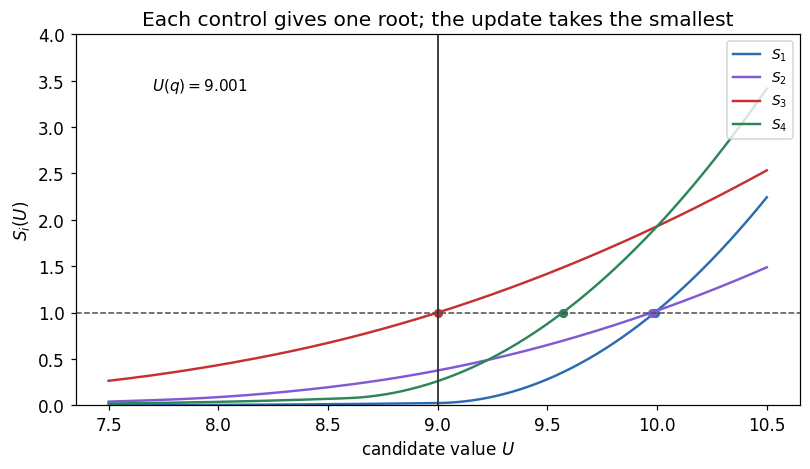

In [16]:
grid = np.linspace(7.5, 10.5, 600)
fig, ax = plt.subplots(figsize=(7.5, 4.4))
colours = ["#2b6cb0", "#805ad5", "#c53030", "#2f855a"]

for i, (u, U_i) in enumerate(zip(controls, solutions)):
    _, _, _, _, rho, g, U_neigh = update_for(u)
    S = np.array([(rho * np.maximum(0.0, U - U_neigh) ** 2).sum() for U in grid])
    ax.plot(grid, S, color=colours[i], lw=1.6, label=r"$S_%d$" % (i + 1))
    ax.plot([U_i], [1.0], "o", color=colours[i], ms=5)

ax.axhline(1.0, color="0.3", lw=1, ls="--")
ax.axvline(min(solutions), color="0.2", lw=1.2)
ax.annotate(r"$U(q) = %.3f$" % min(solutions),
            xy=(min(solutions), 3.0), xytext=(7.7, 3.4), fontsize=10)
ax.set_xlabel(r"candidate value $U$")
ax.set_ylabel(r"$S_i(U)$")
ax.set_ylim(0, 4)
ax.set_title(r"Each control gives one root; the update takes the smallest")
ax.legend(loc="upper right", fontsize=9)
fig.tight_layout()
save(fig, "09_update_roots")
plt.show()

Each curve leaves zero at its own threshold, the first active neighbour, and
crosses the dashed line at its root. The update takes the leftmost crossing.

The same picture explains the state system of notebook 4. The four operational
modes add, at each point and in each mode $s$, one more constraint,
$U(q, s) \le \min_{s' \ne s} U(q, s') + c(q) T(s, s')$, handled in the same
way: one more term in the maximum, one more candidate root, and the minimum
decides whether the mode changes.

<a id='6'></a>
## 6. What the solver runs

`Selling.Decomposition`, used above, is agd's Python version of Selling's
algorithm. The kernel runs the same algorithm in CUDA, on agd's form of
section 3, keeps the offsets within about 35 degrees of the control and orients
them, then evaluates the quadratic update of section 4 per grid point, per
state, per iteration:

- the relaxed form and the selection of the offsets are in
  `external/agd/agd/Eikonal/HFM_CUDA/cuda/Geometry_.h` (`self_outer_relax_v`)
  and `Decomp_v_.h`, the decomposition in three dimensions in `Geometry3.h`
  (`decomp_m`);
- the kernel that consumes the weights and offsets is
  `external/agd/agd/Eikonal/HFM_CUDA/cuda/DubinsState_.h`;
- the transition costs $T(s,s')$ are loaded as $T^{-2}$ and enter the same sum of
  squares, which is why they combine with $c(q)$ multiplicatively.

The arithmetic of sections 4 and 5 therefore runs a few million times per solve
on the GPU, once per point of the $(x, y, \theta, s)$ grid and per sweep.

---

Previous: [8. Benchmark metrics](08_benchmark_metrics.ipynb)  